In [1]:
#Import Library
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.cluster import KMeans
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import (silhouette_score, silhouette_samples, davies_bouldin_score,
                             accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay)
RS = 42
URUTAN = ["Valuasi Relatif Rendah", "Valuasi Relatif Sedang", "Valuasi Relatif Tinggi"]

In [2]:
#Konfigurasi Data
# "positif" : hanya saham dengan PER > 0 dan PBV > 0, winsorizing atas P95 (sesuai proposal)
# "semua"   : seluruh saham kecuali yang tidak memiliki nilai (FREN),
#             winsorizing dua sisi P5-P95 karena ada nilai negatif ekstrem
DATA = "positif"
P_BAWAH = 5 if DATA == "semua" else None
print(f"Data yang digunakan: {DATA}")

Data yang digunakan: positif


In [3]:
#Dataset
df = pd.read_excel("Dataset Oktober.xlsx")
df = df[["Kode Saham", "Sektor", "PER", "PBV", "ROE %", "DER"]].copy()

df.loc[df["Kode Saham"] == "KETR", "Sektor"] = "Infrastructures"
df.loc[df["Kode Saham"] == "VICI", "Sektor"] = "Consumer Non-Cyclicals"

print(f"Jumlah data   : {len(df)} saham")
print(f"Jumlah sektor : {df['Sektor'].nunique()}")
df.head()

Jumlah data   : 960 saham
Jumlah sektor : 11


,Kode Saham,Sektor,PER,PBV,ROE %,DER
0,AADI,Energy,5.97,1.21,20.28,0.61
1,AALI,Consumer Non-Cyclicals,8.24,0.63,7.59,0.17
2,ABBA,Consumer Cyclicals,-4.78,-0.99,0.00,-2.87
3,ABDA,Financials,22.46,1.69,7.54,0.58
4,ABMM,Industrials,4.97,0.45,8.99,1.30


In [4]:
mv = pd.DataFrame({"jumlah_missing": df.isna().sum(),
                   "persen": (df.isna().mean() * 100).round(3)})
print(mv)
print(f"\nTotal baris yang memuat missing value: {df.isna().any(axis=1).sum()}")
df[df.isna().any(axis=1)]

            jumlah_missing  persen
Kode Saham               0   0.000
Sektor                   0   0.000
PER                      1   0.104
PBV                      1   0.104
ROE %                    1   0.104
DER                      1   0.104

Total baris yang memuat missing value: 1


,Kode Saham,Sektor,PER,PBV,ROE %,DER
328,FREN,Infrastructures,NaN,NaN,NaN,NaN


In [5]:
#Penanganan Missing Value
n_awal = len(df)
df = df.dropna(subset=["PER", "PBV"]).reset_index(drop=True)
print(f"Sebelum: {n_awal} | Sesudah: {len(df)} | Dihapus: {n_awal - len(df)}")
print(f"Sisa missing value: {df[['PER', 'PBV']].isna().sum().sum()}")

Sebelum: 960 | Sesudah: 959 | Dihapus: 1
Sisa missing value: 0


In [6]:
n_sebelum = len(df)
print(f"PER <= 0 : {(df['PER'] <= 0).sum()} saham")
print(f"PBV <= 0 : {(df['PBV'] <= 0).sum()} saham")

if DATA == "positif":
    df = df[(df["PER"] > 0) & (df["PBV"] > 0)].reset_index(drop=True)
else:
    print("\nDATA = 'semua': saham dengan PER/PBV <= 0 tetap digunakan")
print(f"\nSebelum: {n_sebelum} | Sesudah: {len(df)} | Dihapus: {n_sebelum - len(df)}")

PER <= 0 : 324 saham
PBV <= 0 : 54 saham

Sebelum: 959 | Sesudah: 627 | Dihapus: 332


In [7]:
#Winsorizing Upper Only  P95
n = len(df)
L = 1 + (n - 1) * 0.95
print(f"n = {n}  ->  L = 1 + ({n}-1) x 0,95 = {L:.4f}\n")

for c in ["PER", "PBV"]:
    urut = np.sort(df[c].values)
    i = int(L)
    batas = np.percentile(df[c], 95)
    bawah = np.percentile(df[c], P_BAWAH) if P_BAWAH else -np.inf
    n_cap = ((df[c] > batas) | (df[c] < bawah)).sum()
    df[c + "_w"] = np.clip(df[c], bawah, batas)
    print(f"{c}: X{i} = {urut[i-1]:.4f}, X{i+1} = {urut[i]:.4f}  ->  "
          f"P95 = {batas:.4f}" + (f", P{P_BAWAH} = {bawah:.4f}" if P_BAWAH else "")
          + f"  ({n_cap} saham dipotong)")

df[["PER", "PER_w", "PBV", "PBV_w"]].describe().T

n = 627  ->  L = 1 + (627-1) x 0,95 = 595.7000

PER: X595 = 192.2100, X596 = 200.5100  ->  P95 = 198.0200  (32 saham dipotong)
PBV: X595 = 9.5200, X596 = 9.7100  ->  P95 = 9.6530  (32 saham dipotong)


,count,mean,std,min,25%,50%,75%,max
PER,627.0,94.946587,813.805784,0.31,8.135,14.39,37.905,19728.830
PER_w,627.0,36.846348,50.478068,0.31,8.135,14.39,37.905,198.020
PBV,627.0,3.893700,22.003677,0.04,0.630,1.19,2.340,467.340
PBV_w,627.0,2.128319,2.469208,0.04,0.630,1.19,2.340,9.653


In [8]:
#Standardisasi Relatif Sektor
stat_sektor = df.groupby("Sektor").agg(
    n=("Kode Saham", "count"),
    mu_PER=("PER_w", "mean"), sigma_PER=("PER_w", lambda s: s.std(ddof=1)),
    mu_PBV=("PBV_w", "mean"), sigma_PBV=("PBV_w", lambda s: s.std(ddof=1)))
stat_sektor

,n,mu_PER,sigma_PER,mu_PBV,sigma_PBV
Sektor,,,,,
Basic Materials,80,26.942250,37.425092,1.607075,1.802635
Consumer Cyclicals,80,35.002125,46.973544,2.044525,2.519647
Consumer Non-Cyclicals,96,33.039167,52.380367,2.778615,2.932667
Energy,66,37.262576,50.708534,2.706439,2.974580
Financials,82,35.225732,46.170753,1.472476,1.840280
Healthcare,32,52.021250,67.573875,2.487281,2.168951
Industrials,42,32.863571,46.152983,2.296881,2.728375
Infrastructures,40,33.901500,43.667897,2.324475,2.459714
Properties & Real Estate,53,41.283396,51.337272,1.463396,1.875883


In [9]:
g = df.groupby("Sektor")
for c in ["PER", "PBV"]:
    df[c + "_z"] = g[c + "_w"].transform(lambda s: (s - s.mean()) / s.std(ddof=1))

X_k = df[["PER_z", "PBV_z"]].values

# verifikasi: mean tiap sektor harus 0, std harus 1
cek = df.groupby("Sektor")[["PER_z", "PBV_z"]].agg(["mean", "std"]).round(4)
print("Verifikasi (mean ~0, std ~1):")
cek

Verifikasi (mean ~0, std ~1):

PER_z      PBV_z     
                           mean  std  mean  std
Sektor                                         
Basic Materials             0.0  1.0   0.0  1.0
Consumer Cyclicals          0.0  1.0   0.0  1.0
Consumer Non-Cyclicals      0.0  1.0  -0.0  1.0
Energy                      0.0  1.0   0.0  1.0
Financials                 -0.0  1.0  -0.0  1.0
Healthcare                 -0.0  1.0  -0.0  1.0
Industrials                 0.0  1.0   0.0  1.0
Infrastructures             0.0  1.0   0.0  1.0
Properties & Real Estate   -0.0  1.0  -0.0  1.0
Technology                 -0.0  1.0  -0.0  1.0
Transportation & Logistic  -0.0  1.0   0.0  1.0

 K       WCSS  Silhouette      DBI
 2 543.546512    0.683581 0.784153
 3 368.017823    0.655856 0.810437
 4 234.722877    0.643842 0.669780
 5 177.489364    0.533568 0.728799
 6 148.613708    0.526640 0.746378

Silhouette tertinggi : K = 2
DBI terendah         : K = 4
Silhouette K = 3     : 0.6559 -> memenuhi >= 0,51, K = 3 digunakan
K pembanding analisis sensitivitas: 4


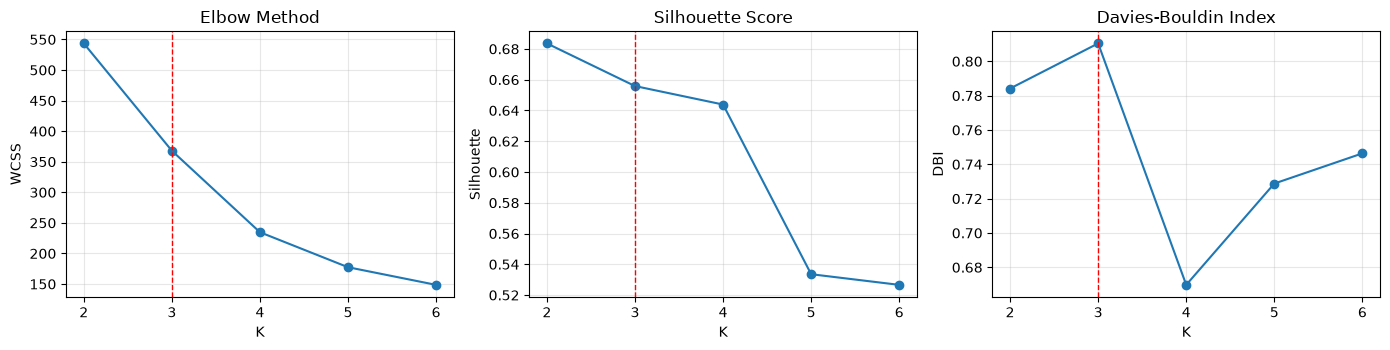

In [10]:
#K-Means Clustering
hasil = []
for k in range(2, 7):
    km = KMeans(n_clusters=k, n_init=50, random_state=RS).fit(X_k)
    hasil.append({"K": k, "WCSS": km.inertia_,
                  "Silhouette": silhouette_score(X_k, km.labels_),
                  "DBI": davies_bouldin_score(X_k, km.labels_)})
df_k = pd.DataFrame(hasil)
print(df_k.to_string(index=False))

k_sil = int(df_k.loc[df_k.Silhouette.idxmax(), "K"])
k_dbi = int(df_k.loc[df_k.DBI.idxmin(), "K"])
sil_3 = df_k.loc[df_k.K == 3, "Silhouette"].item()
print(f"\nSilhouette tertinggi : K = {k_sil}")
print(f"DBI terendah         : K = {k_dbi}")
print(f"Silhouette K = 3     : {sil_3:.4f} -> "
      + ("memenuhi >= 0,51, K = 3 digunakan" if sil_3 >= 0.51 else "di bawah 0,51"))

# K = 2 (Silhouette) hanya membentuk kategori Rendah dan Tinggi, jadi analisis
# sensitivitas memakai K = 4 (saran DBI dan Elbow) sebagai pembanding.
K_PEMBANDING = 4
print(f"K pembanding analisis sensitivitas: {K_PEMBANDING}")

fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
for a, col, judul in zip(ax, ["WCSS", "Silhouette", "DBI"],
                         ["Elbow Method", "Silhouette Score", "Davies-Bouldin Index"]):
    a.plot(df_k.K, df_k[col], marker="o")
    a.axvline(3, color="red", ls="--", lw=1)
    a.set(title=judul, xlabel="K", ylabel=col, xticks=df_k.K)
    a.grid(alpha=.3)
plt.tight_layout(); plt.show()

In [11]:
K = 3
kmeans = KMeans(n_clusters=K, n_init=50, random_state=RS).fit(X_k)
df["cluster"] = kmeans.labels_

print(f"WCSS       : {kmeans.inertia_:.4f}")
print(f"Silhouette : {silhouette_score(X_k, df['cluster']):.4f}")
print(f"DBI        : {davies_bouldin_score(X_k, df['cluster']):.4f}")
print(f"Iterasi    : {kmeans.n_iter_}")

centroid = pd.DataFrame(kmeans.cluster_centers_, columns=["PER_z", "PBV_z"])
centroid["jumlah"] = df["cluster"].value_counts().sort_index()
centroid

WCSS       : 368.0178
Silhouette : 0.6559
DBI        : 0.8104
Iterasi    : 8


,PER_z,PBV_z,jumlah
0,-0.387197,-0.319254,507
1,1.456942,2.493392,66
2,1.854638,-0.050039,54


In [12]:
def beri_label(centroid):
    skor = centroid.mean(axis=1)                 # rata-rata PERz dan PBVz centroid
    urut = np.argsort(skor)                      # skor terendah -> tertinggi
    label = {int(i): "Valuasi Relatif Sedang" for i in urut}
    label[int(urut[0])] = "Valuasi Relatif Rendah"
    label[int(urut[-1])] = "Valuasi Relatif Tinggi"
    return label, skor


c = kmeans.cluster_centers_
label, skor = beri_label(c)
for i in np.argsort(skor):
    print(f"Cluster {i}: PERz = {c[i,0]:+.4f}, PBVz = {c[i,1]:+.4f}, "
          f"skor = {skor[i]:+.4f}  ->  {label[i]}")

df["label"] = df["cluster"].map(label)

Cluster 0: PERz = -0.3872, PBVz = -0.3193, skor = -0.3532  ->  Valuasi Relatif Rendah
Cluster 2: PERz = +1.8546, PBVz = -0.0500, skor = +0.9023  ->  Valuasi Relatif Sedang
Cluster 1: PERz = +1.4569, PBVz = +2.4934, skor = +1.9752  ->  Valuasi Relatif Tinggi


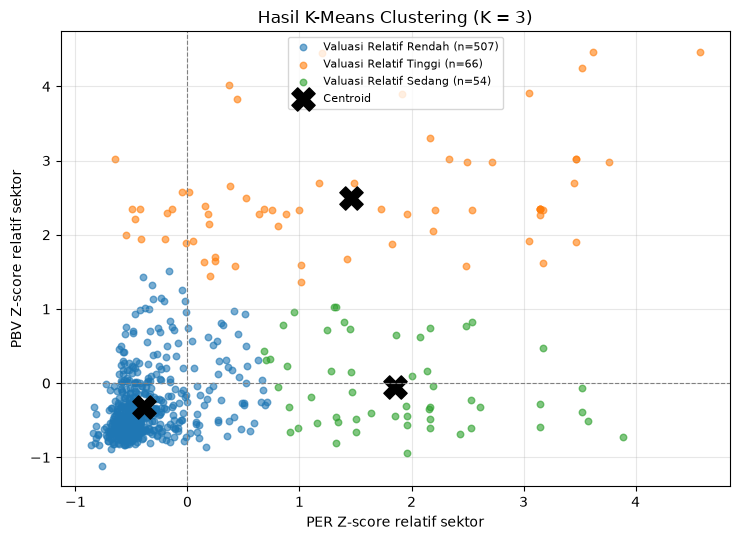

In [13]:
fig, ax = plt.subplots(figsize=(7.5, 5.5))
for i in range(K):
    m = df["cluster"] == i
    ax.scatter(df.loc[m, "PER_z"], df.loc[m, "PBV_z"], s=22, alpha=.6,
               label=f"{label[i]} (n={m.sum()})")
ax.scatter(c[:, 0], c[:, 1], marker="X", s=280, c="black", label="Centroid")
ax.axhline(0, color="gray", ls="--", lw=.8); ax.axvline(0, color="gray", ls="--", lw=.8)
ax.set(xlabel="PER Z-score relatif sektor", ylabel="PBV Z-score relatif sektor",
       title="Hasil K-Means Clustering (K = 3)")
ax.legend(fontsize=8); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

In [14]:
#Analisis Hasil Clustering
df["silhouette"] = silhouette_samples(X_k, df["cluster"])
ringkasan = pd.DataFrame({
    "jumlah": df["label"].value_counts(),
    "proporsi (%)": (df["label"].value_counts(normalize=True) * 100).round(2),
    "silhouette rata-rata": df.groupby("label")["silhouette"].mean().round(4),
}).reindex(URUTAN)
ringkasan

,jumlah,proporsi (%),silhouette rata-rata
label,,,
Valuasi Relatif Rendah,507,80.86,0.7283
Valuasi Relatif Sedang,54,8.61,0.4214
Valuasi Relatif Tinggi,66,10.53,0.2912


In [15]:
#Profil Cluster
posisi = (pd.DataFrame(c, columns=["PERz centroid", "PBVz centroid"])
          .rename(index=label).reindex(URUTAN).round(4))
print("Posisi centroid (skala Z):")
print(posisi, "\n")

profil = df.groupby("label")[["PER_w", "PBV_w"]].agg(["mean", "median", "min", "max"])
profil.reindex(URUTAN).round(4)

Posisi centroid (skala Z):
                        PERz centroid  PBVz centroid
Valuasi Relatif Rendah        -0.3872        -0.3193
Valuasi Relatif Sedang         1.8546        -0.0500
Valuasi Relatif Tinggi         1.4569         2.4934 



PER_w                           PBV_w               \
                            mean   median    min     max    mean median   min   
label                                                                           
Valuasi Relatif Rendah   17.0275   11.220   0.31   97.80  1.3490   0.99  0.04   
Valuasi Relatif Sedang  135.5263  128.605  66.63  198.02  1.8674   1.51  0.12   
Valuasi Relatif Tinggi  108.3530   97.465   4.54  198.02  8.3287   9.47  4.03   

                               
                          max  
label                          
Valuasi Relatif Rendah  7.220  
Valuasi Relatif Sedang  5.340  
Valuasi Relatif Tinggi  9.653

label                      Valuasi Relatif Rendah  Valuasi Relatif Sedang  \
Sektor                                                                      
Basic Materials                                69                       5   
Consumer Cyclicals                             64                       7   
Consumer Non-Cyclicals                         80                       4   
Energy                                         52                       4   
Financials                                     66                      10   
Healthcare                                     23                       5   
Industrials                                    35                       3   
Infrastructures                                35                       1   
Properties & Real Estate                       42                       6   
Technology                                     21                       4   
Transportation & Logistic                      20                       5   

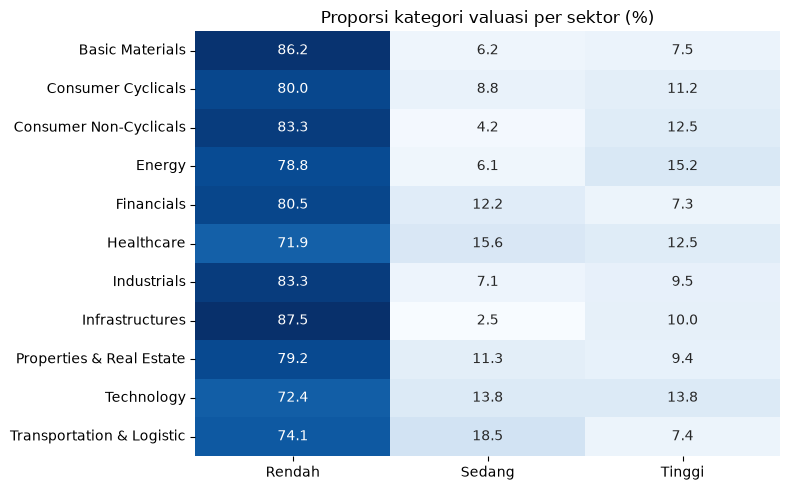

In [16]:
#Tabulasi Silang Label Cluster dan Sektor IDX-IC
tabulasi = pd.crosstab(df["Sektor"], df["label"]).reindex(columns=URUTAN, fill_value=0)
tabulasi["Total"] = tabulasi.sum(axis=1)
print(tabulasi, "\n")

persen = pd.crosstab(df["Sektor"], df["label"], normalize="index").reindex(columns=URUTAN) * 100
fig, ax = plt.subplots(figsize=(8, 5))
sns.heatmap(persen, annot=True, fmt=".1f", cmap="Blues", cbar=False, ax=ax,
            xticklabels=[k.replace("Valuasi Relatif ", "") for k in URUTAN])
ax.set(title="Proporsi kategori valuasi per sektor (%)", xlabel="", ylabel="")
plt.tight_layout(); plt.show()

Profil cluster K = 3:
          Label    n  Proporsi (%)   Z-PER   Z-PBV  PER_med  PBV_med  ROE_med  DER_med
Cluster                                                                               
0        Rendah  507          80.9 -0.3872 -0.3193   11.220     0.99    8.150    0.690
2        Sedang   54           8.6  1.8546 -0.0500  128.605     1.51    0.900    0.620
1        Tinggi   66          10.5  1.4569  2.4934   97.465     9.47   13.105    1.135 

Profil cluster K = 4:
                                   Label    n  Proporsi (%)   Z-PER   Z-PBV  PER_med  PBV_med  ROE_med  DER_med
Cluster                                                                                                        
1                                 Rendah  469          74.8 -0.4113 -0.4128    10.61    0.920     7.97    0.690
0        Sedang (PER setara, PBV tinggi)   77          12.3  0.1369  1.3542    36.81    4.940    14.96    0.940
3        Sedang (PER tinggi, PBV setara)   47           7.5  1.9911 -0.

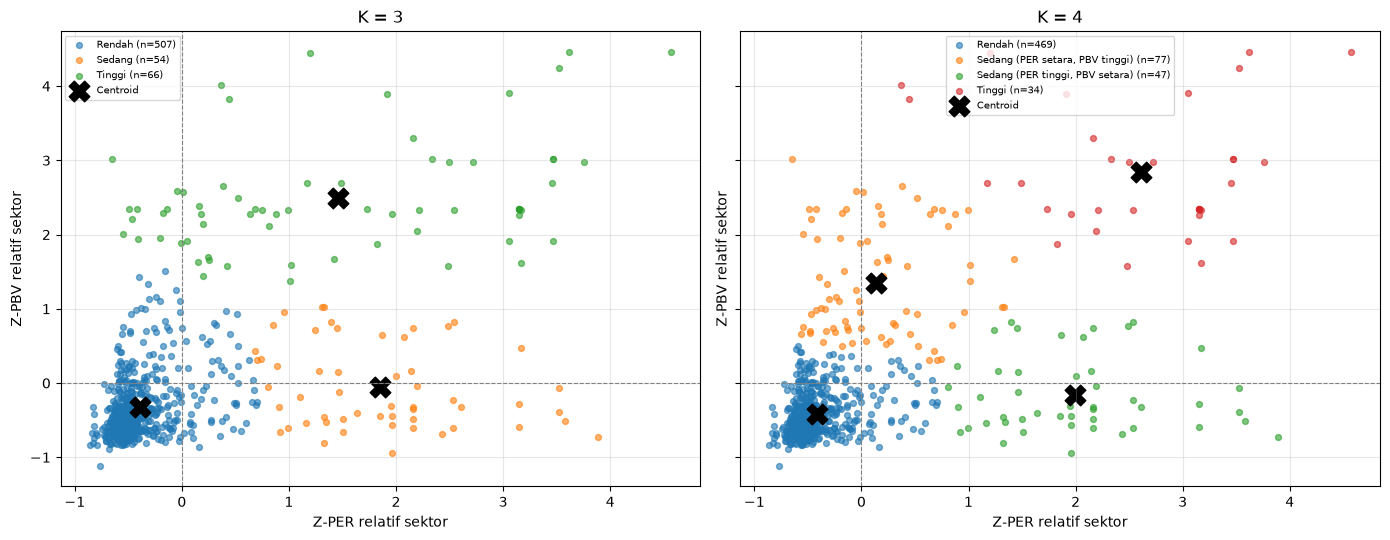

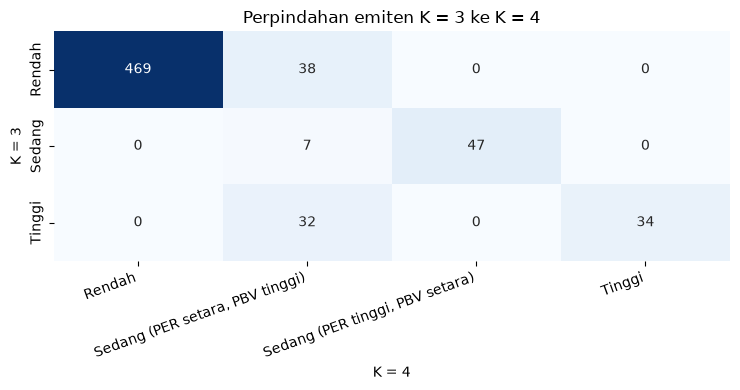

In [17]:
#Analisis Sensitivitas K = 3 vs K = 4 (Clustering)
def nama_label(centroid):
    """Label 3.1.6; bila ada lebih dari satu cluster Sedang, dibedakan menurut posisi centroid."""
    lab, skor_k = beri_label(centroid)
    tengah = [int(i) for i in np.argsort(skor_k)][1:-1]
    if len(tengah) > 1:
        arah = lambda z: "tinggi" if z > 0.5 else "rendah" if z < -0.5 else "setara"
        for i in tengah:
            lab[i] = (f"Valuasi Relatif Sedang (PER {arah(centroid[i, 0])}, "
                      f"PBV {arah(centroid[i, 1])})")
    return lab, skor_k


def profil_k(km_k):
    lab, skor_k = nama_label(km_k.cluster_centers_)
    d = df.assign(c=km_k.labels_)
    prof = d.groupby("c").agg(n=("Kode Saham", "count"),
                              PER_med=("PER", "median"), PBV_med=("PBV", "median"),
                              ROE_med=("ROE %", "median"), DER_med=("DER", "median"))
    prof.insert(0, "Label", pd.Series(lab).str.replace("Valuasi Relatif ", ""))
    prof.insert(2, "Proporsi (%)", (prof["n"] / len(d) * 100).round(1))
    prof.insert(3, "Z-PER", km_k.cluster_centers_[prof.index, 0])
    prof.insert(4, "Z-PBV", km_k.cluster_centers_[prof.index, 1])
    prof = prof.loc[np.argsort(skor_k)]
    prof.index.name = "Cluster"
    return lab, prof


km_4 = KMeans(n_clusters=K_PEMBANDING, n_init=50, random_state=RS).fit(X_k)
label_3, profil_3 = profil_k(kmeans)
label_4, profil_4 = profil_k(km_4)
df["label_k4"] = pd.Series(km_4.labels_).map(label_4).values

print("Profil cluster K = 3:")
print(profil_3.round(4).to_string(), "\n")
print(f"Profil cluster K = {K_PEMBANDING}:")
print(profil_4.round(4).to_string(), "\n")

urut_4 = [label_4[int(i)] for i in profil_4.index]
pendek = lambda s: s.replace("Valuasi Relatif ", "")
perpindahan = (pd.crosstab(df["label"], df["label_k4"])
               .reindex(index=URUTAN, columns=urut_4, fill_value=0))
print(f"Perpindahan emiten (baris: K = 3, kolom: K = {K_PEMBANDING}):")
print(perpindahan.rename(index=pendek, columns=pendek).to_string())

fig, ax = plt.subplots(1, 2, figsize=(14, 5.5), sharex=True, sharey=True)
for a, km_k, lab, prof in ((ax[0], kmeans, label_3, profil_3), (ax[1], km_4, label_4, profil_4)):
    for i in prof.index:
        m = km_k.labels_ == i
        a.scatter(X_k[m, 0], X_k[m, 1], s=18, alpha=.6, label=f"{pendek(lab[i])} (n={m.sum()})")
    cen = km_k.cluster_centers_
    a.scatter(cen[:, 0], cen[:, 1], marker="X", s=220, c="black", label="Centroid")
    a.axhline(0, color="gray", ls="--", lw=.8); a.axvline(0, color="gray", ls="--", lw=.8)
    a.set(title=f"K = {km_k.n_clusters}", xlabel="Z-PER relatif sektor",
          ylabel="Z-PBV relatif sektor")
    a.legend(fontsize=7); a.grid(alpha=.3)
plt.tight_layout(); plt.show()

fig, ax = plt.subplots(figsize=(7.5, 4))
sns.heatmap(perpindahan, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
            xticklabels=[pendek(s) for s in urut_4], yticklabels=[pendek(s) for s in URUTAN])
ax.set(title=f"Perpindahan emiten K = 3 ke K = {K_PEMBANDING}",
       xlabel=f"K = {K_PEMBANDING}", ylabel="K = 3")
plt.xticks(rotation=20, ha="right"); plt.tight_layout(); plt.show()


In [18]:
print("Missing value:")
print(df[["ROE %", "DER"]].isna().sum())
df = df.dropna(subset=["ROE %", "DER"]).reset_index(drop=True)
print(f"\nData untuk Random Forest: {len(df)} saham")

print("\nRentang nilai:")

for c_ in ["ROE %", "DER"]:
    print(f"  {c_:6s}: min = {df[c_].min():.4f}, max = {df[c_].max():.4f}, "
          f"nilai negatif = {(df[c_] < 0).sum()}")

print("\nWinsorizing " + (f"dua sisi P{P_BAWAH}-P95:" if P_BAWAH else "upper-only P95:"))
for c_ in ["ROE %", "DER"]:
    batas = np.percentile(df[c_], 95)
    bawah = np.percentile(df[c_], P_BAWAH) if P_BAWAH else -np.inf
    n_cap = ((df[c_] > batas) | (df[c_] < bawah)).sum()
    print(f"  {c_:6s}: P95 = {batas:.4f}" + (f", P{P_BAWAH} = {bawah:.4f}" if P_BAWAH else "")
          + f"  ({n_cap} saham dipotong)")
    df[c_ + "_w"] = np.clip(df[c_], bawah, batas)

X = df[["ROE %_w", "DER_w"]]
y = df["label"]

Missing value:
ROE %    0
DER      0
dtype: int64

Data untuk Random Forest: 627 saham

Rentang nilai:
  ROE % : min = 0.0100, max = 281.5700, nilai negatif = 0
  DER   : min = 0.0000, max = 17.0500, nilai negatif = 0

Winsorizing upper-only P95:
  ROE % : P95 = 31.2940  (32 saham dipotong)
  DER   : P95 = 4.9800  (32 saham dipotong)


In [19]:
#Random Forest
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RS)

print(f"Data latih : {len(X_tr)}")
print(f"Data uji   : {len(X_te)}\n")
print(pd.DataFrame({"latih": y_tr.value_counts(), "uji": y_te.value_counts()}).reindex(URUTAN))

Data latih : 501
Data uji   : 126

                        latih  uji
label                             
Valuasi Relatif Rendah    405  102
Valuasi Relatif Sedang     43   11
Valuasi Relatif Tinggi     53   13


In [20]:
#Model Awal
rf = RandomForestClassifier(n_estimators=100, class_weight="balanced", random_state=RS)
rf.fit(X_tr, y_tr)
print(rf)

RandomForestClassifier(class_weight='balanced', random_state=42)


                        precision    recall  f1-score   support

Valuasi Relatif Rendah     0.8723    0.8039    0.8367       102
Valuasi Relatif Sedang     0.5000    0.5455    0.5217        11
Valuasi Relatif Tinggi     0.2500    0.3846    0.3030        13

              accuracy                         0.7381       126
             macro avg     0.5408    0.5780    0.5538       126
          weighted avg     0.7756    0.7381    0.7542       126



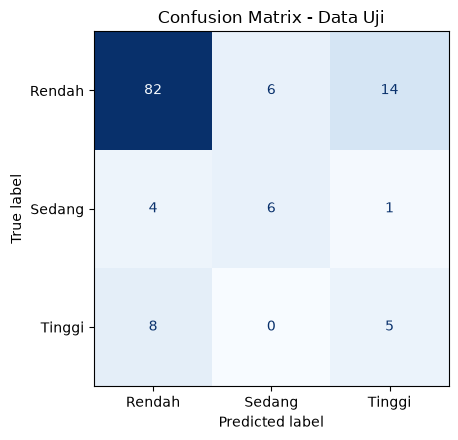

In [21]:
#Evaluasi Confusion Matrix, Accruracy, Precision, Recall, F1-Score
y_pred = rf.predict(X_te)
print(classification_report(y_te, y_pred, labels=URUTAN, digits=4))

fig, ax = plt.subplots(figsize=(5.5, 4.5))
ConfusionMatrixDisplay(confusion_matrix(y_te, y_pred, labels=URUTAN),
                       display_labels=[k.replace("Valuasi Relatif ", "") for k in URUTAN]
                       ).plot(ax=ax, cmap="Blues", colorbar=False)
ax.set_title("Confusion Matrix - Data Uji")
plt.tight_layout(); plt.show()

In [22]:
importance = pd.Series(rf.feature_importances_, index=["ROE", "DER"], name="Feature Importance")
print(importance.round(4), "\n")

print("Rata-rata ROE dan DER per kategori valuasi:")
df.groupby("label")[["ROE %", "DER"]].mean().reindex(URUTAN).round(4)

ROE    0.6405
DER    0.3595
Name: Feature Importance, dtype: float64 

Rata-rata ROE dan DER per kategori valuasi:


,ROE %,DER
label,,
Valuasi Relatif Rendah,10.8622,1.1699
Valuasi Relatif Sedang,1.5048,1.1246
Valuasi Relatif Tinggi,28.6674,2.4470


Rata-rata Z-score per kategori (0 = rata-rata seluruh saham):
                           PER     PBV     ROE     DER
label                                                 
Valuasi Relatif Rendah -0.3926 -0.3156  0.0425 -0.0515
Valuasi Relatif Sedang  1.9549 -0.1057 -1.0310 -0.0771
Valuasi Relatif Tinggi  1.4166  2.5111  0.5168  0.4584 

Median nilai asli per kategori:
                           PER   PBV  ROE %   DER
label                                            
Valuasi Relatif Rendah   11.22  0.99   8.15  0.69
Valuasi Relatif Sedang  128.60  1.51   0.90  0.62
Valuasi Relatif Tinggi   97.46  9.47  13.10  1.14


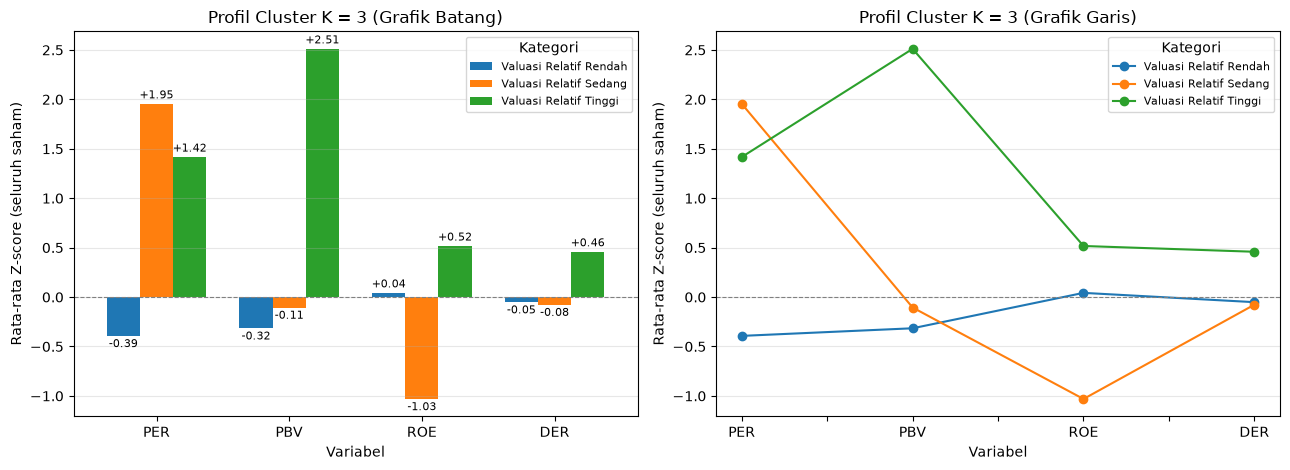

In [23]:
#//Tambahan Uji Program//
#Profil Cluster (Grafik Batang dan Grafik Garis)
# PER, PBV, ROE, DER hasil winsorizing distandardisasi terhadap seluruh saham
# (bukan per sektor) agar keempatnya dapat dibandingkan pada satu sumbu.
var = ["PER_w", "PBV_w", "ROE %_w", "DER_w"]
z_prof = ((df[var] - df[var].mean()) / df[var].std()).groupby(df["label"]).mean().reindex(URUTAN)
z_prof.columns = ["PER", "PBV", "ROE", "DER"]
print("Rata-rata Z-score per kategori (0 = rata-rata seluruh saham):")
print(z_prof.round(4), "\n")

print("Median nilai asli per kategori:")
print(df.groupby("label")[["PER", "PBV", "ROE %", "DER"]].median().reindex(URUTAN).round(2))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.8))
z_prof.T.plot(kind="bar", ax=ax1, rot=0, width=.75)
for bar in ax1.containers:
    ax1.bar_label(bar, fmt="%+.2f", fontsize=8, padding=2)
ax1.set(title="Profil Cluster K = 3 (Grafik Batang)", xlabel="Variabel",
        ylabel="Rata-rata Z-score (seluruh saham)")

z_prof.T.plot(marker="o", ax=ax2)
ax2.set(title="Profil Cluster K = 3 (Grafik Garis)", xlabel="Variabel",
        ylabel="Rata-rata Z-score (seluruh saham)")
for ax in (ax1, ax2):
    ax.axhline(0, color="gray", ls="--", lw=.8)
    ax.legend(title="Kategori", fontsize=8); ax.grid(alpha=.3, axis="y")
plt.tight_layout(); plt.show()


Jumlah data uji per fold:
                        Fold 1  Fold 2  Fold 3  Fold 4  Fold 5
label                                                         
Valuasi Relatif Rendah     102     102     101     101     101
Valuasi Relatif Sedang      11      10      11      11      11
Valuasi Relatif Tinggi      13      14      13      13      13 



 Fold       Pembobotan  Accuracy  Precision  Recall  F1-Score  Recall Rendah  Recall Sedang  Recall Tinggi
    1         balanced    0.7619     0.5122  0.5477    0.5271         0.8529         0.6364         0.1538
    1 Tanpa pembobotan    0.8413     0.6335  0.5580    0.5678         0.9608         0.6364         0.0769
    2         balanced    0.6587     0.4736  0.5639    0.4942         0.7059         0.7000         0.2857
    2 Tanpa pembobotan    0.7937     0.5575  0.4881    0.5076         0.9216         0.4000         0.1429
    3         balanced    0.7600     0.5662  0.5649    0.5627         0.8416         0.5455         0.3077
    3 Tanpa pembobotan    0.7920     0.6177  0.4748    0.5086         0.9208         0.2727         0.2308
    4         balanced    0.7760     0.5429  0.5762    0.5567         0.8614         0.6364         0.2308
    4 Tanpa pembobotan    0.8080     0.6116  0.4637    0.5000         0.9505         0.3636         0.0769
    5         balanced    0.7600     

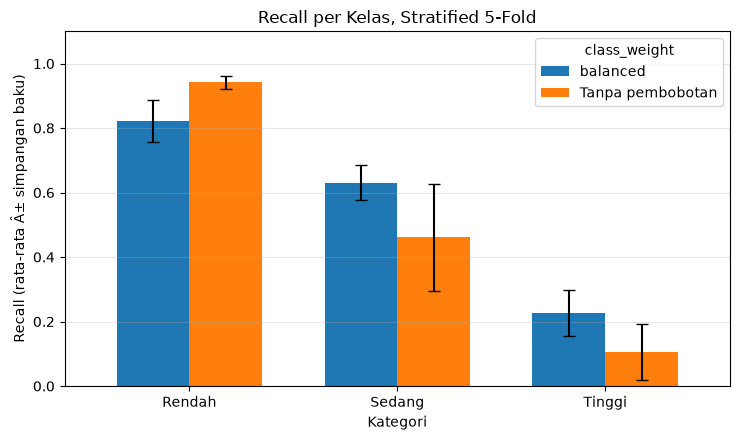

In [24]:
#//Tambahan Uji Program//
#K-Fold Cross Validation (Stratified, k = 5)
# Menguji penanganan kelas tidak seimbang: setiap fold melatih Random Forest
# dengan dan tanpa class_weight="balanced", parameter lain sama dengan model awal.
# Model awal (confusion matrix, Feature Importance) tetap dari pembagian 80:20.
from sklearn.model_selection import StratifiedKFold

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RS)
print("Jumlah data uji per fold:")
print(pd.DataFrame({f"Fold {f}": y.iloc[i_te].value_counts().reindex(URUTAN)
                    for f, (_, i_te) in enumerate(skf.split(X, y), 1)}), "\n")

baris = []
for fold, (i_tr, i_te) in enumerate(skf.split(X, y), 1):
    y_te_f = y.iloc[i_te]
    for nama, cw in [("balanced", "balanced"), ("Tanpa pembobotan", None)]:
        rf_f = RandomForestClassifier(n_estimators=100, class_weight=cw, random_state=RS)
        rf_f.fit(X.iloc[i_tr], y.iloc[i_tr])
        pred = rf_f.predict(X.iloc[i_te])
        rec = recall_score(y_te_f, pred, labels=URUTAN, average=None, zero_division=0)
        baris.append({"Fold": fold, "Pembobotan": nama,
                      "Accuracy": accuracy_score(y_te_f, pred),
                      "Precision": precision_score(y_te_f, pred, average="macro", zero_division=0),
                      "Recall": recall_score(y_te_f, pred, average="macro", zero_division=0),
                      "F1-Score": f1_score(y_te_f, pred, average="macro", zero_division=0),
                      "Recall Rendah": rec[0], "Recall Sedang": rec[1], "Recall Tinggi": rec[2]})

hasil_kf = pd.DataFrame(baris)
print(hasil_kf.round(4).to_string(index=False), "\n")

ringkas_kf = (hasil_kf.drop(columns="Fold").groupby("Pembobotan", sort=False)
              .agg(["mean", "std"]).T.unstack(level=1))
print("Rata-rata dan simpangan baku 5 fold:")
print(ringkas_kf.round(4))

kelas = ["Recall Rendah", "Recall Sedang", "Recall Tinggi"]
rata = hasil_kf.groupby("Pembobotan", sort=False)[kelas].mean().T
sb = hasil_kf.groupby("Pembobotan", sort=False)[kelas].std().T
ax = rata.plot(kind="bar", yerr=sb, rot=0, figsize=(7.5, 4.5), capsize=4, width=.7)
ax.set_xticklabels(["Rendah", "Sedang", "Tinggi"])
ax.set(title="Recall per Kelas, Stratified 5-Fold", xlabel="Kategori",
       ylabel="Recall (rata-rata Â± simpangan baku)", ylim=(0, 1.1))
ax.legend(title="class_weight"); ax.grid(alpha=.3, axis="y")
plt.tight_layout(); plt.show()


In [25]:
#Analisis Sensitivitas K = 3 vs K = 4 (Ringkasan Metrik)
def evaluasi_rf(y_k):
    """Prosedur Random Forest yang sama dengan model utama, untuk label K lain."""
    X_tr_k, X_te_k, y_tr_k, y_te_k = train_test_split(
        X, y_k, test_size=0.2, stratify=y_k, random_state=RS)
    rf_k = RandomForestClassifier(n_estimators=100, class_weight="balanced",
                                  random_state=RS).fit(X_tr_k, y_tr_k)
    pred = rf_k.predict(X_te_k)
    metrik = {
        "RF Accuracy": accuracy_score(y_te_k, pred),
        "RF Precision (macro)": precision_score(y_te_k, pred, average="macro", zero_division=0),
        "RF Recall (macro)": recall_score(y_te_k, pred, average="macro", zero_division=0),
        "RF F1-Score (macro)": f1_score(y_te_k, pred, average="macro", zero_division=0),
        "RF F1-Score (weighted)": f1_score(y_te_k, pred, average="weighted", zero_division=0),
        "Kelas terkecil di data uji": int(y_te_k.value_counts().min()),
    }
    return metrik, pd.Series(rf_k.feature_importances_, index=["ROE", "DER"])


def ringkas(km_k, y_k):
    metrik_rf, imp = evaluasi_rf(y_k)
    return {"WCSS": km_k.inertia_,
            "Silhouette": silhouette_score(X_k, km_k.labels_),
            "Davies-Bouldin": davies_bouldin_score(X_k, km_k.labels_),
            "Cluster terkecil (saham)": int(np.bincount(km_k.labels_).min()),
            **metrik_rf}, imp


m_3, imp_3 = ringkas(kmeans, df["label"])
m_4, imp_4 = ringkas(km_4, df["label_k4"])

# True bila makin besar makin baik
LEBIH_BESAR = {"WCSS": False, "Silhouette": True, "Davies-Bouldin": False}
k3, k4 = "K = 3", f"K = {K_PEMBANDING}"
sensitivitas = pd.DataFrame({k3: m_3, k4: m_4})
sensitivitas["Lebih baik"] = [
    "-" if np.isclose(a, b) else (k3 if (a > b) == LEBIH_BESAR.get(m, True) else k4)
    for m, a, b in zip(sensitivitas.index, sensitivitas[k3], sensitivitas[k4])]

print(f"Unggul {k3}: {(sensitivitas['Lebih baik'] == k3).sum()} metrik")
print(f"Unggul {k4}: {(sensitivitas['Lebih baik'] == k4).sum()} metrik\n")
print("Feature Importance RF:")
print(pd.DataFrame({k3: imp_3, k4: imp_4}).round(4), "\n")
sensitivitas.round(4)


Unggul K = 3: 8 metrik
Unggul K = 4: 2 metrik

Feature Importance RF:
      K = 3   K = 4
ROE  0.6405  0.6336
DER  0.3595  0.3664 



,K = 3,K = 4,Lebih baik
WCSS,368.0178,234.7229,K = 4
Silhouette,0.6559,0.6438,K = 3
Davies-Bouldin,0.8104,0.6698,K = 4
Cluster terkecil (saham),54.0000,34.0000,K = 3
RF Accuracy,0.7381,0.6587,K = 3
RF Precision (macro),0.5408,0.4673,K = 3
RF Recall (macro),0.5780,0.5526,K = 3
RF F1-Score (macro),0.5538,0.4954,K = 3
RF F1-Score (weighted),0.7542,0.6843,K = 3
Kelas terkecil di data uji,11.0000,7.0000,K = 3
